# 02 · Análise exploratória (EDA) 

**Objetivo:** identificar o que mais se associa ao NPS, o que gera detratores, se existe um ponto de ruptura na experiência e quais perfis de cliente têm NPS mais alto e mais baixo.

**Entrada:** `data/nps_tratado.csv` · **Saída:** gráficos em `reports/figuras/` e conclusões que alimentam os slides.

In [1]:
import pandas as pd
df = pd.read_csv("../data/nps_tratado.csv")
df.shape   # esperado: (2346, 20)

(2346, 20)

Irei usar o método spearman para conferir as correlações de cada variável com o NPS

In [2]:
fatores = [ "delivery_time_days", "delivery_delay_days", "delivery_attempts", "customer_service_contacts", "resolution_time_days", "complaints_count", "freight_value", 
"discount_value", "order_value", "items_quantity", "payment_installments", "csat_internal_score", "repeat_purchase_30d", "customer_age", "customer_tenure_months" ]  

corr = df[fatores + ["nps_score"]].corr(method="spearman")["nps_score"]
corr.drop("nps_score").sort_values()

delivery_delay_days         -0.568439
complaints_count            -0.499177
customer_service_contacts   -0.339367
resolution_time_days        -0.191817
delivery_time_days          -0.065298
freight_value               -0.038847
customer_age                -0.006895
customer_tenure_months      -0.005535
items_quantity               0.008635
discount_value               0.015959
payment_installments         0.027568
order_value                  0.033711
delivery_attempts            0.035747
repeat_purchase_30d          0.494558
csat_internal_score          0.546679
Name: nps_score, dtype: float64

#### Irei separar as variáveis em três grupos para facilitar a analise:

**Fatores operacionais**, **Medidas que acompanham a nota** e **Perfil do cliente**

In [3]:
fatores = [ "delivery_time_days", "delivery_delay_days", "delivery_attempts", "customer_service_contacts", "resolution_time_days", "complaints_count", "freight_value",
 "discount_value", "order_value", "items_quantity", "payment_installments" ]  #Fatores operacionais

corr = df[fatores + ["nps_score"]].corr(method="spearman")["nps_score"]
corr.drop("nps_score").sort_values()

delivery_delay_days         -0.568439
complaints_count            -0.499177
customer_service_contacts   -0.339367
resolution_time_days        -0.191817
delivery_time_days          -0.065298
freight_value               -0.038847
items_quantity               0.008635
discount_value               0.015959
payment_installments         0.027568
order_value                  0.033711
delivery_attempts            0.035747
Name: nps_score, dtype: float64

In [4]:
fatores = [ "csat_internal_score", "repeat_purchase_30d" ]  #Medidas que acompanham a nota

corr = df[fatores + ["nps_score"]].corr(method="spearman")["nps_score"]
corr.drop("nps_score").sort_values()

repeat_purchase_30d    0.494558
csat_internal_score    0.546679
Name: nps_score, dtype: float64

In [5]:
fatores = [ "customer_age", "customer_tenure_months" ]  #Perfil do cliente

corr = df[fatores + ["nps_score"]].corr(method="spearman")["nps_score"]
corr.drop("nps_score").sort_values()

customer_age             -0.006895
customer_tenure_months   -0.005535
Name: nps_score, dtype: float64

In [6]:
df[["delivery_delay_days", "complaints_count"]].corr(method="spearman") #verirficando correlação entre as duas variáveis que mais impactam a nota NPS

,delivery_delay_days,complaints_count
delivery_delay_days,1.000000,0.194452
complaints_count,0.194452,1.000000


A maior pontuação é do atraso na entrega, comparando com um fator corretalato que é o tempo de entrega, vemos que o que mais frusta o cliente é a sua entrega passar do tempo de entrega estimado passado para ele.

A idade e tempo de casa, pela correlação, não há relação detectável.

Por esta simples analise, os principais fatores para agir, baseado nos resultados de spearman, são: atraso na entrega e contagem de reclamações. Pois são as duas maiores correlação com a queda do NPS e, pela verificação de correlação entre eles ser fraca(0,19), entendemos que são probleas distintos que demandam ações separadas.

O CSAT e a recompra não são causa, mas mostram que quanto maior forem seus resultados, maior a tendencia de um bom NPS.

In [7]:
df.groupby("delivery_delay_days")["nps_score"].agg(["mean", "count"])

,mean,count
delivery_delay_days,,
0,6.850735,272
1,5.554860,607
2,4.586520,638
3,3.457054,482
4,2.407143,224
5,1.393333,90
6,1.252174,23
7,0.375000,8
8,0.000000,2


In [8]:
(df["nps_class"] == "detrator").groupby(df["delivery_delay_days"]).mean() * 100

delivery_delay_days
0     51.838235
1     74.135091
2     87.931034
3     96.887967
4     99.107143
5    100.000000
6    100.000000
7    100.000000
8    100.000000
Name: nps_class, dtype: float64

In [9]:
(df["delivery_delay_days"] == 0).mean() * 100 #verificar pedidos entregues no prazo

np.float64(11.594202898550725)

não há um degrau, e sim uma perda constante de cerca de 1 ponto de nota por dia de atraso. Mesmo com 1 dia de atraso, analisando só essa variável, já vimos um salto de ~22 pontos percentuais de detratores e a partir de 3 dias de atraso, quase todos viram detratores. Para tentar resolver, já que atrasar é regra e não exceção(apenas ~12% dos pedidos chegam sem atraso), há duas frentes: (1)podem ser extraidos os dados das entregas, de forma a encontrar a média de dias de atraso e aumentar o tempo de entrega na hora que o cliente finaliza a compra para englobar o tempo da transportadora + média de atraso geral, assumindo o risco de queda na conversão; ou (2)verificar transportadoras que tenham um melhor tempo de entrega e confiabilidade.

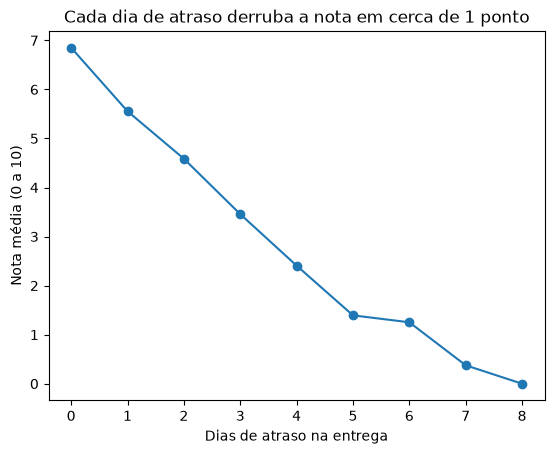

In [10]:
import matplotlib.pyplot as plt

media = df.groupby("delivery_delay_days")["nps_score"].mean()
ax = media.plot(marker="o")
ax.set_xlabel("Dias de atraso na entrega")
ax.set_ylabel("Nota média (0 a 10)")
ax.set_title("Cada dia de atraso derruba a nota em cerca de 1 ponto")   
plt.savefig("../reports/figuras/nps_por_atraso.png", dpi=150, bbox_inches="tight")
plt.show()